# Week 1: Digital images and computational foundations

This is the **lecture companion**, not a programming tutorial. The code is intentionally short. Focus on predicting and interpreting the result before running each experiment.

The course images are searched below 

```
COURSE_IMAGE_DIRS = [
    Path("../../../data-external/img"),  # preferred course layout
    Path("../../img"),
    Path("../../../img"),
    Path("../../data-external/img"),
    Path("../img"),
    Path("data-external/img"),
    Path("img"),
]

_IMAGE_EXTENSIONS = (
    ".tif",
    ".tiff",
    ".png",
    ".jpg",
    ".jpeg",
)
´´´
If a requested image cannot be found, the loader falls back to a standard `skimage.data` image.

In [ ]:
from pathlib import Path
import warnings

import numpy as np
import matplotlib.pyplot as plt
from skimage import color, data, io, util

try:
    import oip
    oip_available = True
except Exception as exc:
    oip_available = False
    print('Could not import oip:')
    print(repr(exc))

print('oip available:', oip_available)

## 1. Load two images and inspect the data

A loader can be given either a **course-image name** or an explicit path. The `dtype` argument controls the numerical representation returned to us.

In [ ]:
gray8 = oip.load_grey("IMG_5051-8bit.jpg", dtype=np.uint8)
rgb = oip.load_rgb("IMG_5051-rgb8bit.jpg", dtype=np.uint8)
grayf = oip.load_grey("IMG_5051-8bit.jpg", dtype=float)

# Important Week 1 questions: what are the shape and dtype of an image array?

gray_shape = gray8.shape
gray_dtype = gray8.dtype


print(f"gray8 : shape={gray_shape}, dtype={gray_dtype}, range=({gray8.min()}, {gray8.max()})")
print(f"grayf : shape={grayf.shape}, dtype={grayf.dtype}, range=({grayf.min():.3f}, {grayf.max():.3f})")
print(f"rgb   : shape={rgb.shape}, dtype={rgb.dtype}, range=({rgb.min()}, {rgb.max()})")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(gray8, cmap="gray")
ax[0].set_title("grayscale image")
ax[1].imshow(rgb)
ax[1].set_title("RGB image")
for a in ax:
    a.axis("off")
plt.tight_layout()

**Discuss:** `gray8` and `grayf` represent the same image. What changed, and what did not? Why does the RGB image have one more array dimension?

## 2. Coordinates, indexing, and cropping

In [ ]:
gray = gray8
h, w = gray.shape
row, col = h // 2, w // 2
print(f"Pixel at image coordinate (u={col}, v={row}) = gray[{row}, {col}] = {gray[row, col]}")

r0, r1 = h // 3, 2 * h // 3
c0, c1 = w // 3, 2 * w // 3


crop = gray[r0:r1, c0:c1]


fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(gray, cmap="gray")
ax[0].set_title("original")
ax[1].imshow(crop, cmap="gray")
ax[1].set_title("cropped region")
for a in ax:
    a.axis("off")
plt.tight_layout()

## 3. Spatial sampling experiment

In [ ]:
factors = [1, 2, 4, 8]
fig, ax = plt.subplots(1, len(factors), figsize=(14, 4))
for a, f in zip(ax, factors):
    
    sampled = gray[::f, ::f]

    a.imshow(sampled, cmap="gray", interpolation="nearest")
    a.set_title(f"every {f} sample(s)\n{sampled.shape}")
    a.axis("off")
plt.tight_layout()

**Discuss:** Which information is lost as the sampling factor increases? Is the numerical range of the retained pixels changed?

## 4. Quantisation experiment

In [ ]:
def quantise_8bit_image(image, levels):
    """Quantise an 8-bit image to `levels` equally spaced intensities."""
    x = oip.ensure_float(image)
    q = np.round(x * (levels - 1)) / (levels - 1)
    return oip.ensure_uint8(q)


levels_list = [256, 16, 4, 2]
fig, ax = plt.subplots(1, len(levels_list), figsize=(14, 4))
for a, levels in zip(ax, levels_list):
    
    q = quantise_8bit_image(gray, levels)

    a.imshow(q, cmap="gray", vmin=0, vmax=255)
    a.set_title(f"{levels} levels")
    a.axis("off")
plt.tight_layout()

**Discuss:** How is reducing intensity levels different from reducing spatial samples?

## 5. Quantifying the change with a norm

In [ ]:
reference = oip.ensure_float(gray)
for levels in [256, 64, 16, 4, 2]:
    q = oip.ensure_float(quantise_8bit_image(gray, levels))
    error = q - reference

    
    rms = np.sqrt(np.mean(error**2))


    l2 = np.linalg.norm(error)
    print(f"{levels:3d} levels: RMS error = {rms:.6f}, L2 norm = {l2:10.4f}")

A visual difference can now be represented by a numerical objective. This is the first bridge to optimisation: later we will choose an image or parameters by **minimising** such objectives.

## 6. Element-wise operation: a simple mask

In [ ]:
g = oip.ensure_float(gray)
h, w = g.shape
y, x = np.ogrid[:h, :w]
radius = min(h, w) * 0.30
mask = (x - w/2)**2 + (y - h/2)**2 <= radius**2
masked = g * mask

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(g, cmap="gray")
ax[0].set_title("image")
ax[1].imshow(mask, cmap="gray")
ax[1].set_title("binary mask")
ax[2].imshow(masked, cmap="gray")
ax[2].set_title("image * mask")
for a in ax:
    a.axis("off")
plt.tight_layout()

Here `image * mask` is an **element-wise** multiplication. It is not the same operation as the matrix product `image @ mask`.

## 7. RGB channels are array slices

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(14, 4))
ax[0].imshow(rgb)
ax[0].set_title("RGB")
for c, name in enumerate(["red channel", "green channel", "blue channel"]):
    ax[c + 1].imshow(rgb[:, :, c], cmap="gray")
    ax[c + 1].set_title(name)
for a in ax:
    a.axis("off")
plt.tight_layout()

## Loader examples

The same functions also work with an explicit path or a standard sample image:

```python
load_grey("camera", dtype=np.float32)
load_rgb("coffee", dtype=np.uint8)
load_rgb("../../data-external/img/my_image.tif", dtype=np.uint16)
```

If a requested course image is unavailable, a standard image is used so that the notebook remains runnable.

## Exit questions

<div class="alert alert-block alert-info">Answer the questions below, then click <b>Check answers</b>. Use them to check that the main ideas of the demo are clear before you leave.</div>


In [ ]:
from IPython.display import IFrame, display, Image, Markdown

poll_url = (
    "https://pollev-embeds.com/"
    "multiple_choice_polls/R3RjIWGBKMLF437n5S1q0/respond"
)

display(Markdown("### Exit poll"))

# Try to show the poll inline
display(IFrame(src=poll_url, width="100%", height=600))

# Always provide a QR fallback underneath
display(Markdown(
    "**If the embedded poll does not appear, scan the QR code below:**"
))



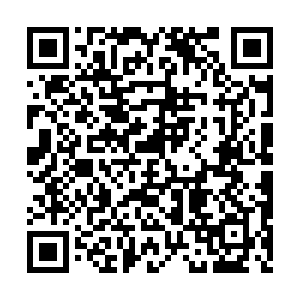